# Civil Comments Toxicity Classification


## 1. Environment and Imports


In [1]:
# Select the existing UV environment as the notebook kernel.
import gc
import hashlib
import json
import math
import os
import platform
import random
import re
import shutil
import sys
import time
import unicodedata
import uuid
from importlib.metadata import version
from itertools import combinations, islice, product
from pathlib import Path

ROOT = Path.cwd()  # Change this if the kernel starts outside the project.
os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "huggingface"))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import DatasetDict, load_dataset
from IPython.display import HTML, display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm
from transformers import (
    AutoConfig, AutoModel, AutoTokenizer, DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 110)
print("Kernel:", sys.executable)
print("Python:", platform.python_version())
display(pd.DataFrame({"package": ["torch", "transformers", "datasets", "numpy", "pandas", "scikit-learn"],
                      "version": [version(p) for p in ["torch", "transformers", "datasets", "numpy", "pandas", "scikit-learn"]]}))


c:\Users\MLDL_02\miniconda3\envs\llm\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Kernel: c:\Users\MLDL_02\miniconda3\envs\llm\python.exe
Python: 3.10.22


,package,version
0,torch,2.14.1+cu126
1,transformers,5.20.2
2,datasets,5.1.0
3,numpy,2.2.6
4,pandas,2.3.3
5,scikit-learn,1.7.2


## 2. Configuration and Reproducibility


In [ ]:
CONFIG = {'model_name': 'distilbert/distilbert-base-uncased',
 'model_revision': 'main',
 'seed': 42,
 'label_threshold': 0.5,
 'train_size': 20000,
 'validation_size': 6000,
 'test_size': 10000,
 'max_length': 256,
 'batch_size': 16,
 'gradient_accumulation_steps': 2,
 'baseline_epochs': 10,
 'baseline_learning_rate': 0.001,
 'baseline_weight_decay': 0.01,
 'fine_tune_epochs': 3,
 'early_stopping_patience': 1,
 'warmup_ratio': 0.1,
 'head_learning_rate_multiplier': 5.0,
 'class_weighting': 'balanced',
 'untuned': {'learning_rate': 2e-05, 'weight_decay': 0.01, 'dropout': 0.1},
 'search': {'trials': 4,
            'learning_rate': [1e-05, 3e-05, 5e-05],
            'weight_decay': [0.0, 0.01, 0.1],
            'dropout': [0.1, 0.2]},
 'bootstrap_repetitions': 500,
 'lime_samples': 512,
 'lime_features': 10}

DATA_SOURCE = "hub"  # Use "local" to reuse the four downloaded Parquet files.
DATA_DIR = ROOT
RUN_DIR = ROOT / "artifacts" / f"notebook_{uuid.uuid4().hex[:8]}"
RUN_DIR.mkdir(parents=True, exist_ok=False)
SPLITS = ("train", "validation", "test")
SCORE_COLUMNS = ("toxicity", "severe_toxicity", "obscene", "threat",
                 "insult", "identity_attack", "sexual_explicit")
LABEL_NAMES = ["not toxic", "toxic"]
MODEL_NAMES = ("frozen", "untuned", "tuned")
COLORS = {"frozen": "#4776b4", "untuned": "#e69f00", "tuned": "#169b81"}
assert 0 < CONFIG["label_threshold"] < 1
assert 4 <= CONFIG["max_length"] <= 512
assert CONFIG["gradient_accumulation_steps"] >= 1


In [3]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
    if torch.backends.cudnn.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def choose_device(requested="auto"):
    if requested != "auto":
        return torch.device(requested)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n")


seed_everything(CONFIG["seed"])
device = choose_device()
write_json(RUN_DIR / "config.json", CONFIG)
print("Device:", device)
print("Output:", RUN_DIR)
print(f"Toxic label: toxicity >= {CONFIG['label_threshold']}")


Device: cuda
Output: d:\Assignment\artifacts\notebook_818d3cc9
Toxic label: toxicity >= 0.5


## 3. Load the Official Dataset Splits


In [4]:
if DATA_SOURCE == "hub":
    raw = load_dataset("google/civil_comments")
elif DATA_SOURCE == "local":
    files = {name: sorted(str(p) for p in DATA_DIR.glob(f"{name}-*.parquet")) for name in SPLITS}
    if any(not paths for paths in files.values()):
        raise FileNotFoundError("Missing local train, validation, or test Parquet files.")
    raw = load_dataset("parquet", data_files=files)
else:
    raise ValueError("DATA_SOURCE must be 'hub' or 'local'.")

assert all(name in raw for name in SPLITS)
assert all(set(("text",) + SCORE_COLUMNS) <= set(raw[name].column_names) for name in SPLITS)
display(raw)
display(pd.DataFrame({"column": raw["train"].column_names,
                      "type": [str(raw["train"].features[c]) for c in raw["train"].column_names]}))


DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})

,column,type
0,text,Value('string')
1,toxicity,Value('float32')
2,severe_toxicity,Value('float32')
3,obscene,Value('float32')
4,threat,Value('float32')
5,insult,Value('float32')
6,identity_attack,Value('float32')
7,sexual_explicit,Value('float32')


## 4. Full-Split Data Quality and Label Analysis


In [5]:
def text_key(text):
    # Normalization is ONLY for duplicate detection. Model input remains the original text.
    normalized = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text).casefold()).strip()
    return hashlib.blake2b(normalized.encode("utf-8"), digest_size=16).hexdigest()


def scan_split(split, threshold=0.5):
    """Bounded text batches; compact numeric arrays for the full-split audit."""
    n = len(split)
    keys = np.empty(n, dtype="S32")
    exact_keys = np.empty(n, dtype="S32")
    scores = np.empty(n, dtype=np.float32)
    chars = np.zeros(n, dtype=np.int32)
    words = np.zeros(n, dtype=np.int32)
    valid = np.ones(n, dtype=bool)
    nulls = {c: 0 for c in split.column_names}
    invalid_scores = {c: 0 for c in SCORE_COLUMNS}
    offset = 0
    for batch in split.iter(batch_size=8192):
        count = len(batch["text"])
        for col in split.column_names:
            nulls[col] += sum(x is None for x in batch[col])
        for col in SCORE_COLUMNS:
            values = np.asarray(batch[col], dtype=float)
            invalid_scores[col] += int((~np.isfinite(values) | (values < 0) | (values > 1)).sum())
        scores[offset:offset + count] = np.asarray(batch["toxicity"], dtype=np.float32)
        for j, value in enumerate(batch["text"], offset):
            text = value if isinstance(value, str) else ""
            keys[j] = text_key(text)
            exact_keys[j] = hashlib.blake2b(text.encode("utf-8"), digest_size=16).hexdigest()
            chars[j] = len(text)
            words[j] = len(text.split())
            valid[j] = bool(text.strip())
        offset += count
    valid &= np.isfinite(scores) & (scores >= 0) & (scores <= 1)
    return {"keys": keys, "exact_keys": exact_keys, "scores": scores, "chars": chars,
            "words": words, "valid": valid, "labels": (scores >= threshold).astype(np.int64),
            "nulls": nulls, "invalid_scores": invalid_scores}


scans = {}
for name in SPLITS:
    print(f"Auditing {name}: {len(raw[name]):,} rows")
    scans[name] = scan_split(raw[name], CONFIG["label_threshold"])

summary_rows, quality_rows = [], []
for name, scan in scans.items():
    valid_scores = scan["scores"][np.isfinite(scan["scores"])]
    unique_keys = np.unique(scan["keys"])
    conflicts = np.intersect1d(np.unique(scan["keys"][scan["labels"] == 0]),
                               np.unique(scan["keys"][scan["labels"] == 1]))
    summary_rows.append({
        "split": name, "rows": len(raw[name]), "not_toxic": int((scan["labels"] == 0).sum()),
        "toxic": int(scan["labels"].sum()), "toxic_rate": float(scan["labels"].mean()),
        "majority_accuracy": float(1 - scan["labels"].mean()),
        "median_words": float(np.median(scan["words"])),
        "p95_words": float(np.quantile(scan["words"], 0.95)),
        "exact_duplicates": len(raw[name]) - len(np.unique(scan["exact_keys"])),
        "normalized_duplicates": len(raw[name]) - len(unique_keys),
        "conflicting_label_groups": len(conflicts),
        "score_equal_0.5": int((scan["scores"] == 0.5).sum()),
        "score_in_0.4_to_0.6": int(((scan["scores"] >= 0.4) & (scan["scores"] <= 0.6)).sum()),
        "score_min": float(valid_scores.min()), "score_max": float(valid_scores.max()),
    })
    for column in raw[name].column_names:
        quality_rows.append({"split": name, "column": column, "nulls": scan["nulls"][column],
                             "invalid_score_count": scan["invalid_scores"].get(column, 0)})

split_summary = pd.DataFrame(summary_rows).set_index("split")
quality_table = pd.DataFrame(quality_rows)
display(split_summary)
display(quality_table)
print("Invalid or blank rows:", {s: int((scans[s]["valid"] == 0).sum()) for s in SPLITS})
split_summary.to_csv(RUN_DIR / "raw_split_summary.csv")
quality_table.to_csv(RUN_DIR / "data_quality.csv", index=False)


Auditing train: 1,804,874 rows
Auditing validation: 97,320 rows
Auditing test: 97,320 rows


,rows,not_toxic,toxic,toxic_rate,majority_accuracy,median_words,p95_words,exact_duplicates,normalized_duplicates,conflicting_label_groups,score_equal_0.5,score_in_0.4_to_0.6,score_min,score_max
split,,,,,,,,,,,,,,
train,1804874,1660540,144334,0.079969,0.920031,35.0,159.0,24051,28366,809,37896,129241,0.0,1.0
validation,97320,89649,7671,0.078822,0.921178,35.0,159.0,474,565,26,2022,6831,0.0,1.0
test,97320,89543,7777,0.079912,0.920088,35.0,159.0,458,573,21,1989,6898,0.0,1.0


,split,column,nulls,invalid_score_count
0,train,text,0,0
1,train,toxicity,0,0
2,train,severe_toxicity,0,0
3,train,obscene,0,0
4,train,threat,0,0
5,train,insult,0,0
6,train,identity_attack,0,0
7,train,sexual_explicit,0,0
8,validation,text,0,0
9,validation,toxicity,0,0


Invalid or blank rows: {'train': 0, 'validation': 0, 'test': 0}


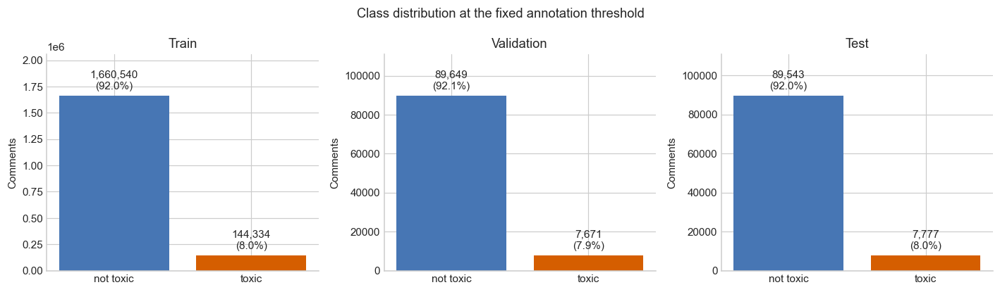

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, name in zip(axes, SPLITS):
    counts = [split_summary.loc[name, "not_toxic"], split_summary.loc[name, "toxic"]]
    bars = ax.bar(LABEL_NAMES, counts, color=["#4776b4", "#d55e00"])
    ax.bar_label(bars, labels=[f"{int(n):,}\n({n / sum(counts):.1%})" for n in counts], padding=4)
    ax.set(title=name.title(), ylabel="Comments", ylim=(0, max(counts) * 1.24))
fig.suptitle("Class distribution at the fixed annotation threshold")
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_class_balance.png", bbox_inches="tight")
plt.show()


## 5. Score Distributions, Text Lengths, and Annotation Correlations


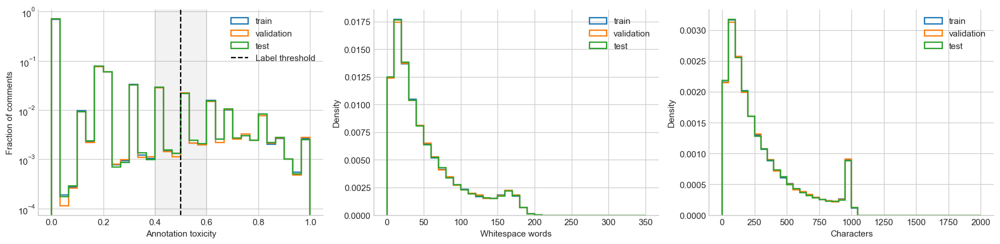

,train,validation,test
annotation_threshold,,,
0.3,0.147428,0.144349,0.146291
0.4,0.111629,0.109834,0.111447
0.5,0.079969,0.078822,0.079912
0.6,0.053416,0.052435,0.053535
0.7,0.032509,0.032450,0.032768


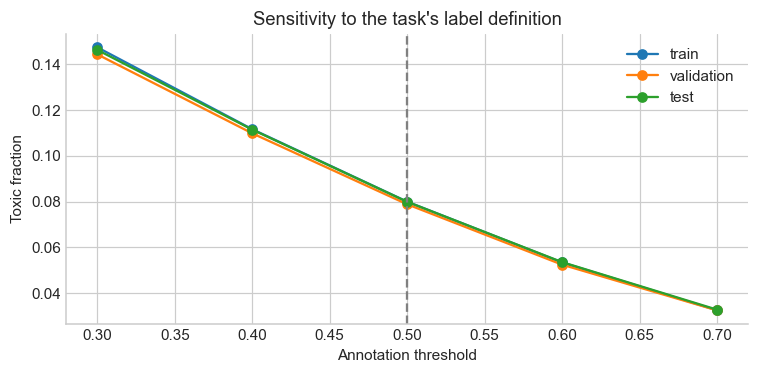

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, scan in scans.items():
    scores = scan["scores"][scan["valid"]]
    axes[0].hist(scores, bins=np.linspace(0, 1, 31), weights=np.ones(len(scores)) / len(scores),
                 histtype="step", linewidth=1.5, label=name)
    axes[1].hist(scan["words"][scan["valid"]], bins=np.arange(0, 351, 10), density=True,
                 histtype="step", linewidth=1.5, label=name)
    axes[2].hist(scan["chars"][scan["valid"]], bins=np.arange(0, 2001, 50), density=True,
                 histtype="step", linewidth=1.5, label=name)
axes[0].axvline(CONFIG["label_threshold"], color="black", linestyle="--", label="Label threshold")
axes[0].axvspan(0.4, 0.6, color="gray", alpha=0.1)
axes[0].set(xlabel="Annotation toxicity", ylabel="Fraction of comments", yscale="log")
axes[1].set(xlabel="Whitespace words", ylabel="Density")
axes[2].set(xlabel="Characters", ylabel="Density")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_distributions.png", bbox_inches="tight")
plt.show()

sensitivity = pd.DataFrame({name: {threshold: float((scans[name]["scores"] >= threshold).mean())
                                        for threshold in (0.3, 0.4, 0.5, 0.6, 0.7)}
                            for name in SPLITS})
sensitivity.index.name = "annotation_threshold"
display(sensitivity)
ax = sensitivity.plot(marker="o", figsize=(7, 3.5), ylabel="Toxic fraction", xlabel="Annotation threshold")
ax.axvline(CONFIG["label_threshold"], color="gray", linestyle="--")
ax.set_title("Sensitivity to the task's label definition")
plt.tight_layout()
plt.savefig(RUN_DIR / "eda_threshold_sensitivity.png", bbox_inches="tight")
plt.show()


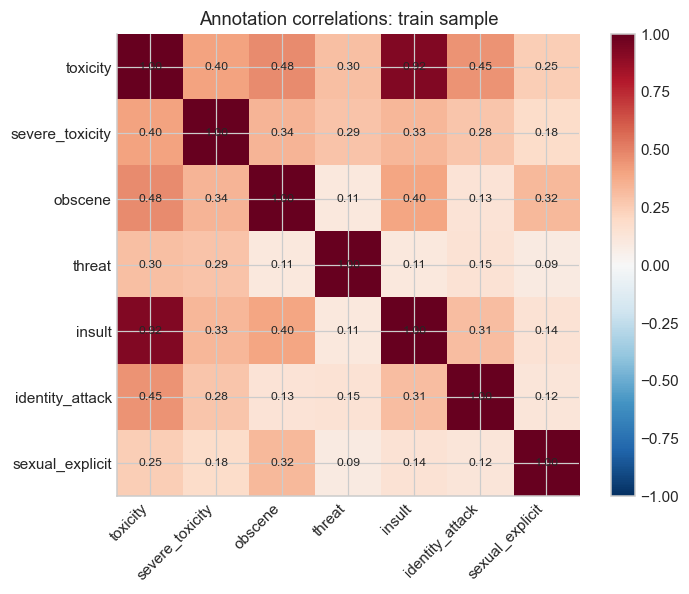

,text,toxicity,label
0,Absolutely not… It is NOT OK to drive drunk or under the influence of anything. Do not put words in my mou...,0.200000,not toxic
1,Sounds like Kagan is a promoter of fear mongering. He almost sounds like he wishes it were true. There a...,0.000000,not toxic
2,I always get suspicious when a public employee has a 1.6 million dollar house. And they can't afford to fu...,0.000000,not toxic
3,You're an idiot,0.948276,toxic
4,"Custom in jails that they beat up and rape rapists. Kill killers, too. Relax. He's gonna lose more weight ...",0.600000,toxic
5,"They weren't stupid enough to invade Iraq in the first place. BTW, your boy Trump bowed to the Saudi king...",0.738462,toxic


In [8]:
# Use a training-only sample for auxiliary-label correlations.
rng = np.random.default_rng(CONFIG["seed"])
correlation_rows = rng.choice(len(raw["train"]), min(20000, len(raw["train"])), replace=False)
annotations = raw["train"].select(correlation_rows.tolist()).select_columns(list(SCORE_COLUMNS)).to_pandas()
correlation = annotations.corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(len(SCORE_COLUMNS)), yticks=range(len(SCORE_COLUMNS)),
       xticklabels=SCORE_COLUMNS, yticklabels=SCORE_COLUMNS, title="Annotation correlations: train sample")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for (i, j), value in np.ndenumerate(correlation.values):
    ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_annotation_correlations.png", bbox_inches="tight")
plt.show()

# Only text is used as input; auxiliary scores are excluded from training.
example_rows = []
for label in (0, 1):
    candidates = np.flatnonzero(scans["train"]["valid"] & (scans["train"]["labels"] == label))
    for row in rng.choice(candidates, min(3, len(candidates)), replace=False):
        item = raw["train"][int(row)]
        example_rows.append({"text": item["text"], "toxicity": item["toxicity"], "label": LABEL_NAMES[label]})
display(pd.DataFrame(example_rows))


## 6. Duplicate Detection and Split Decontamination


,train,validation,test
train,0,1320,1363
validation,1320,0,686
test,1363,686,0


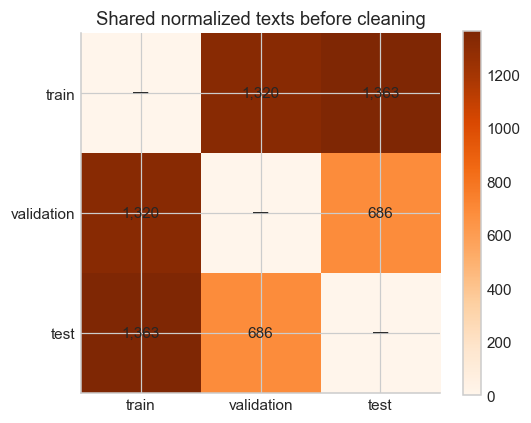

,before,after,removed
train,1804874,1774208,30666
validation,97320,96069,1251
test,97320,96747,573


Normalization detects formatting repeats, not all paraphrases or shared authors.


In [9]:
def clean_indices(scans):
    """Preserve test over validation over train, without inspecting model results.

    Remove within-split repeats and overlaps with higher-priority official splits.
    Original row order determines which occurrence is retained within a split.
    """
    kept = {}
    reserved = np.empty(0, dtype="S32")
    for name in reversed(SPLITS):
        scan = scans[name]
        candidates = np.flatnonzero(scan["valid"])
        _, first = np.unique(scan["keys"][candidates], return_index=True)
        candidates = np.sort(candidates[first])
        candidates = candidates[~np.isin(scan["keys"][candidates], reserved)]
        kept[name] = candidates
        # Reserve all valid higher-priority keys, even if repeated in those splits.
        reserved = np.union1d(reserved, scan["keys"][scan["valid"]])
    return kept


overlap_matrix = pd.DataFrame(0, index=SPLITS, columns=SPLITS)
for a, b in combinations(SPLITS, 2):
    shared = len(np.intersect1d(scans[a]["keys"], scans[b]["keys"]))
    overlap_matrix.loc[a, b] = overlap_matrix.loc[b, a] = shared

display(overlap_matrix)
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(overlap_matrix, cmap="Oranges")
for (i, j), value in np.ndenumerate(overlap_matrix.values):
    ax.text(j, i, "—" if i == j else f"{value:,}", ha="center", va="center")
ax.set(xticks=range(3), yticks=range(3), xticklabels=SPLITS, yticklabels=SPLITS,
       title="Shared normalized texts before cleaning")
fig.colorbar(image, ax=ax)
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_split_overlap.png", bbox_inches="tight")
plt.show()

# Keep first occurrences; reserve test texts, then validation, then train.
clean_rows = clean_indices(scans)
cleaning_summary = pd.DataFrame({"before": {s: len(raw[s]) for s in SPLITS},
                                 "after": {s: len(clean_rows[s]) for s in SPLITS}})
cleaning_summary["removed"] = cleaning_summary["before"] - cleaning_summary["after"]
display(cleaning_summary)
print("Normalization detects formatting repeats, not all paraphrases or shared authors.")


## 7. Stratified Training, Validation, Calibration, and Test Subsets


In [10]:
def stratified_indices(indices, labels, size, seed):
    if size is None or size >= len(indices):
        return np.sort(indices)
    if size < 2 or len(np.unique(labels[indices])) != 2:
        raise ValueError("A stratified subset must support both labels.")
    selected, _ = train_test_split(indices, train_size=size, random_state=seed,
                                   stratify=labels[indices])
    return np.sort(selected)


sampled_rows = {name: stratified_indices(clean_rows[name], scans[name]["labels"],
                                         CONFIG[f"{name}_size"], CONFIG["seed"])
                for name in SPLITS}
selection_rows, calibration_rows = train_test_split(
    sampled_rows["validation"], test_size=0.5, random_state=CONFIG["seed"],
    stratify=scans["validation"]["labels"][sampled_rows["validation"]],
)
indices = {"train": sampled_rows["train"], "selection": np.sort(selection_rows),
           "calibration": np.sort(calibration_rows), "test": sampled_rows["test"]}
parts = DatasetDict()
manifest = {"seed": CONFIG["seed"], "label_threshold": CONFIG["label_threshold"],
            "dataset_source": DATA_SOURCE,
            "dataset_fingerprints": {s: raw[s]._fingerprint for s in SPLITS}, "splits": {}}
seen = set()
for name, rows in indices.items():
    origin = "validation" if name in ("selection", "calibration") else name
    part = raw[origin].select(rows.tolist()).select_columns(["text", "toxicity"])
    part = part.add_column("label", scans[origin]["labels"][rows].tolist())
    part = part.add_column("source_row", rows.tolist())
    part = part.add_column("text_hash", scans[origin]["keys"][rows].astype(str).tolist())
    hashes = set(part["text_hash"])
    assert not hashes & seen, f"Text overlap found in {name}"
    assert len(hashes) == len(part)
    assert set(part["label"]) == {0, 1}, f"Increase the sample size for {name}"
    seen.update(hashes)
    parts[name] = part
    manifest["splits"][name] = {"official_split": origin, "rows": len(part), "source_rows": rows.tolist()}

labels = {name: np.asarray(part["label"], dtype=np.int64) for name, part in parts.items()}
partition_summary = pd.DataFrame([{"partition": name, "rows": len(part),
                                   "toxic": int(labels[name].sum()), "toxic_rate": labels[name].mean()}
                                  for name, part in parts.items()]).set_index("partition")
display(partition_summary)
write_json(RUN_DIR / "split_manifest.json", manifest)
parts.save_to_disk(str(RUN_DIR / "data"))
print("Selection chooses models; calibration chooses score thresholds; test is held out.")
del raw, scans, clean_rows, sampled_rows, seen, annotations
_gc = gc.collect()


,rows,toxic,toxic_rate
partition,,,
train,20000,1599,0.079950
selection,3000,236,0.078667
calibration,3000,236,0.078667
test,10000,798,0.079800


Saving the dataset (1/1 shards): 100%|██████████| 10000/10000 [00:00<00:00, 846376.62 examples/s]


Selection chooses models; calibration chooses score thresholds; test is held out.


## 8. Tokenization and Sequence-Length Coverage


,median_tokens,p95_tokens,p99_tokens,fraction_truncated
partition,,,,
train,48.0,204.0,231.00,0.000650
selection,48.5,204.0,232.00,0.000667
calibration,51.0,201.0,231.01,0.000667
test,48.0,202.0,229.00,0.000800


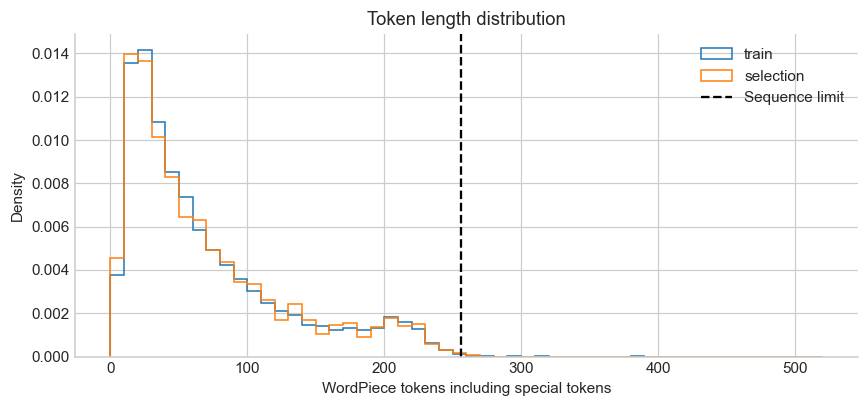

In [11]:
pretrained_config = AutoConfig.from_pretrained(CONFIG["model_name"], revision=CONFIG["model_revision"])
resolved_revision = getattr(pretrained_config, "_commit_hash", None) or CONFIG["model_revision"]
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_name"], revision=resolved_revision, use_fast=True)

token_lengths = {}
for name, part in parts.items():
    lengths = []
    for batch in part.iter(batch_size=512):
        lengths.extend(map(len, tokenizer(batch["text"], truncation=False, verbose=False)["input_ids"]))
    token_lengths[name] = np.asarray(lengths)

coverage = pd.DataFrame([{
    "partition": name, "median_tokens": np.median(lengths), "p95_tokens": np.quantile(lengths, 0.95),
    "p99_tokens": np.quantile(lengths, 0.99),
    "fraction_truncated": float((lengths > CONFIG["max_length"]).mean()),
} for name, lengths in token_lengths.items()]).set_index("partition")
display(coverage)
coverage.to_csv(RUN_DIR / "token_coverage.csv")
fig, ax = plt.subplots(figsize=(8, 3.8))
for name in ("train", "selection"):
    ax.hist(token_lengths[name], bins=np.arange(0, 521, 10), histtype="step", density=True, label=name)
ax.axvline(CONFIG["max_length"], color="black", linestyle="--", label="Sequence limit")
ax.set(xlabel="WordPiece tokens including special tokens", ylabel="Density", title="Token length distribution")
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "eda_token_lengths.png", bbox_inches="tight")
plt.show()


In [12]:
def tokenize_splits(parts, tokenizer, max_length):
    encoded = {}
    for name, part in parts.items():
        encoded[name] = part.map(
            lambda batch: tokenizer(batch["text"], truncation=True, max_length=max_length),
            batched=True, remove_columns=part.column_names, desc=f"Tokenize {name}",
        ).add_column("labels", list(part["label"]))
    return encoded


def loader(dataset, tokenizer, batch_size, seed=42, shuffle=False):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      generator=generator, collate_fn=DataCollatorWithPadding(tokenizer))


encoded = tokenize_splits(parts, tokenizer, CONFIG["max_length"])
eval_loaders = {name: loader(part, tokenizer, CONFIG["batch_size"], CONFIG["seed"])
                for name, part in encoded.items()}
counts = np.bincount(labels["train"], minlength=2)
assert np.all(counts > 0)
class_weights = (len(labels["train"]) / (2 * counts)).astype(np.float32)
if CONFIG["class_weighting"] == "none":
    class_weights = np.ones(2, dtype=np.float32)
weights_cpu = torch.tensor(class_weights)
weights_device = weights_cpu.to(device)
display(pd.DataFrame({"class": LABEL_NAMES, "train_count": counts, "loss_weight": class_weights}))


,class,train_count,loss_weight
0,not toxic,18401,0.543449
1,toxic,1599,6.253909


## 9. Shared BERT-Based Model and Evaluation Metrics


In [13]:
class ToxicityModel(nn.Module):
    def __init__(self, encoder, dropout=0.1):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(encoder.config.hidden_size, 2))

    def encode(self, **inputs):
        hidden = self.encoder(**inputs).last_hidden_state
        mask = inputs["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        return (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

    def forward(self, **inputs):
        return self.head(self.encode(**inputs))


def save_weights(model, path):
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, path)


def load_weights(model, path):
    model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
    return model


@torch.inference_mode()
def predict_texts(model, tokenizer, texts, device, max_length=256, batch_size=16):
    if isinstance(texts, str):
        texts = [texts]
    model.eval()
    probabilities = []
    for start in range(0, len(texts), batch_size):
        batch = tokenizer(list(texts[start:start + batch_size]), padding=True, truncation=True,
                          max_length=max_length, return_tensors="pt")
        batch = {k: v.to(device) for k, v in batch.items()}
        probabilities.append(model(**batch).softmax(-1).cpu().numpy())
    return np.concatenate(probabilities) if probabilities else np.empty((0, 2))


def evaluate(labels, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    return {
        "threshold": float(threshold), "rows": len(labels), "toxic_rows": int(np.sum(labels)),
        "average_precision": float(average_precision_score(labels, scores)),
        "roc_auc": float(roc_auc_score(labels, scores)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(balanced_accuracy_score(labels, predicted)),
        "toxic_precision": float(precision_score(labels, predicted, zero_division=0)),
        "toxic_recall": float(recall_score(labels, predicted, zero_division=0)),
        "toxic_f1": float(f1_score(labels, predicted, zero_division=0)),
        "macro_f1": float(f1_score(labels, predicted, average="macro", zero_division=0)),
        "confusion_matrix": confusion_matrix(labels, predicted, labels=[0, 1]).tolist(),
        "per_class": classification_report(labels, predicted, labels=[0, 1],
                                            target_names=["not toxic", "toxic"],
                                            output_dict=True, zero_division=0),
    }


def select_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    # A deterministic tie-break: choose the higher threshold (fewer flags).
    best = np.flatnonzero(np.isclose(f1, f1.max(), rtol=0, atol=1e-12))[-1]
    return float(thresholds[best])


def bootstrap_differences(labels, reference, candidate, reference_threshold, candidate_threshold,
                          repetitions=500, seed=42):
    """Paired stratified percentile intervals, conditional on this fitted pair.

    Resample the same indices for both models; thresholds remain fixed. These
    intervals do not estimate retraining/seed variance or deployment prevalence shift.
    """
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(labels == c) for c in (0, 1)]
    ap, f1 = [], []
    for _ in range(repetitions):
        idx = np.concatenate([rng.choice(g, len(g), replace=True) for g in groups])
        y, a, b = labels[idx], reference[idx], candidate[idx]
        ap.append(average_precision_score(y, b) - average_precision_score(y, a))
        f1.append(f1_score(y, b >= candidate_threshold, zero_division=0) -
                  f1_score(y, a >= reference_threshold, zero_division=0))
    return {"repetitions": repetitions, "method": "paired stratified percentile bootstrap",
            "difference_direction": "candidate minus frozen baseline",
            "average_precision_difference_95_ci": np.quantile(ap, [0.025, 0.975]).tolist(),
            "toxic_f1_difference_95_ci": np.quantile(f1, [0.025, 0.975]).tolist()}


In [14]:
seed_everything(CONFIG["seed"])
encoder = AutoModel.from_pretrained(CONFIG["model_name"], revision=resolved_revision,
                                     attn_implementation="eager")
model = ToxicityModel(encoder).to(device)
model.encoder.config.save_pretrained(RUN_DIR / "encoder_config")
tokenizer.save_pretrained(RUN_DIR / "tokenizer")
write_json(RUN_DIR / "provenance.json", {
    "model": CONFIG["model_name"], "resolved_revision": resolved_revision,
    "dataset_source": DATA_SOURCE, "device": str(device), "python": platform.python_version(),
    "packages": {p: version(p) for p in ("torch", "transformers", "datasets", "numpy", "pandas", "scikit-learn")},
})
print(f"Encoder parameters: {sum(p.numel() for p in model.encoder.parameters()):,}")
print(f"Head parameters: {sum(p.numel() for p in model.head.parameters()):,}")


c:\Users\MLDL_02\miniconda3\envs\llm\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in D:\Assignment\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\MLDL_02\miniconda3\envs\llm\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses 

Encoder parameters: 66,362,880
Head parameters: 1,538


## 10. Training, Validation, and Learning-Curve Utilities


In [15]:
def encoder_digest(model):
    digest = hashlib.sha256()
    for name, tensor in model.encoder.state_dict().items():
        digest.update(name.encode())
        digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()


def optimizer_groups(model, hyperparameters, config, frozen):
    groups = {}
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        head = name.startswith("head.")
        lr = hyperparameters["learning_rate"]
        if head and not frozen:
            lr *= config["head_learning_rate_multiplier"]
        decay = 0.0 if name.endswith("bias") or "layernorm" in name.lower() or "layer_norm" in name.lower() else hyperparameters["weight_decay"]
        groups.setdefault((lr, decay), []).append(param)
    return [{"params": params, "lr": lr, "weight_decay": decay} for (lr, decay), params in groups.items()]


@torch.no_grad()
def extract_features(model, batches, device, path):
    model.encoder.eval()
    features, labels = [], []
    for batch in batches:
        inputs = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        features.append(model.encode(**inputs).cpu())
        labels.append(batch["labels"])
    features, labels = torch.cat(features), torch.cat(labels)
    torch.save({"features": features, "labels": labels}, path)
    return TensorDataset(features, labels)


In [16]:
def batch_labels(batch, frozen):
    return batch[1] if frozen else batch["labels"]


def batch_logits(model, batch, frozen):
    if frozen:
        return model.head(batch[0].to(device))
    inputs = {key: value.to(device) for key, value in batch.items() if key != "labels"}
    return model(**inputs)


@torch.no_grad()
def evaluate_loader(model, batches, frozen=False):
    model.eval()
    numerator, denominator = 0.0, 0.0
    all_labels, probabilities = [], []
    for batch in batches:
        target = batch_labels(batch, frozen).to(device)
        logits = batch_logits(model, batch, frozen)
        numerator += F.cross_entropy(logits, target, weight=weights_device, reduction="sum").item()
        denominator += weights_device[target].sum().item()
        probabilities.append(logits.softmax(-1)[:, 1].cpu().numpy())
        all_labels.append(target.cpu().numpy())
    y = np.concatenate(all_labels)
    score = np.concatenate(probabilities)
    result = {"loss": numerator / denominator,
              "accuracy": float(accuracy_score(y, score >= 0.5)),
              "average_precision": float(average_precision_score(y, score)),
              "toxic_f1": float(f1_score(y, score >= 0.5, zero_division=0))}
    return result, y, score


def fit_model(model, training_loader, training_eval_loader, validation_loader, hp,
              checkpoint, frozen, max_epochs):
    seed_everything(CONFIG["seed"])
    for parameter in model.encoder.parameters():
        parameter.requires_grad_(not frozen)
    model.head[0].p = hp["dropout"]
    optimizer = torch.optim.AdamW(optimizer_groups(model, hp, CONFIG, frozen))
    accumulation = CONFIG["gradient_accumulation_steps"]
    total_steps = math.ceil(len(training_loader) / accumulation) * max_epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(total_steps * CONFIG["warmup_ratio"]),
        num_training_steps=total_steps,
    )
    best_ap, best_epoch, stale = -1.0, 0, 0
    history = []
    started = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        model.train()
        if frozen:
            model.encoder.eval()
        loss_sum, weight_sum = 0.0, 0.0
        iterator = iter(training_loader)
        progress = tqdm(total=len(training_loader), desc=f"Epoch {epoch}/{max_epochs}", leave=False)
        while group := list(islice(iterator, accumulation)):
            optimizer.zero_grad(set_to_none=True)
            targets = [batch_labels(batch, frozen) for batch in group]
            denominator = sum(weights_cpu[target].sum().item() for target in targets)
            for batch, target_cpu in zip(group, targets):
                logits = batch_logits(model, batch, frozen)
                target = target_cpu.to(device)
                numerator = F.cross_entropy(logits, target, weight=weights_device, reduction="sum")
                (numerator / denominator).backward()
                loss_sum += numerator.detach().item()
                progress.update(1)
            weight_sum += denominator
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
            optimizer.step()
            scheduler.step()
        progress.close()

        # Evaluate both complete datasets at the same epoch checkpoint.
        train_metrics, _, _ = evaluate_loader(model, training_eval_loader, frozen)
        val_metrics, _, _ = evaluate_loader(model, validation_loader, frozen)
        row = {"epoch": epoch, "optimization_loss": loss_sum / weight_sum,
               **{f"train_{key}": value for key, value in train_metrics.items()},
               **{f"val_{key}": value for key, value in val_metrics.items()}}
        if not all(math.isfinite(value) for value in row.values()):
            raise RuntimeError("Non-finite metrics; training stopped before test evaluation.")
        history.append(row)
        print(f"Epoch {epoch}: train loss={row['train_loss']:.4f}, val loss={row['val_loss']:.4f}, "
              f"train acc={row['train_accuracy']:.4f}, val acc={row['val_accuracy']:.4f}, "
              f"val AP={row['val_average_precision']:.4f}")
        if val_metrics["average_precision"] > best_ap + 1e-6:
            best_ap = val_metrics["average_precision"]
            best_epoch, stale = epoch, 0
            save_weights(model, checkpoint)
        else:
            stale += 1
            if stale >= CONFIG["early_stopping_patience"]:
                break

    load_weights(model, checkpoint)
    model.eval()
    result = {"best_epoch": best_epoch, "selection_average_precision": best_ap,
              "history": history, "hyperparameters": hp, "encoder_frozen": frozen,
              "fit_seconds": time.perf_counter() - started,
              "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad)}
    write_json(Path(checkpoint).with_suffix(".json"), result)
    return result


def plot_history(result, title, filename):
    history = pd.DataFrame(result["history"])
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, metric, ylabel in zip(axes, ("loss", "accuracy", "average_precision"),
                                  ("Weighted cross-entropy", "Accuracy at score 0.5", "Average precision")):
        ax.plot(history["epoch"], history[f"train_{metric}"], marker="o", label="Training")
        ax.plot(history["epoch"], history[f"val_{metric}"], marker="o", label="Validation (selection)")
        ax.axvline(result["best_epoch"], color="gray", linestyle=":", label="Selected epoch")
        ax.set(xlabel="Epoch", ylabel=ylabel, xticks=history["epoch"])
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RUN_DIR / filename, bbox_inches="tight")
    plt.show()
    display(history.round(4))


## 11. Frozen Transfer-Learning Baseline


Epoch 1: train loss=0.4952, val loss=0.4807, train acc=0.8252, val acc=0.8393, val AP=0.4008


Epoch 2: train loss=0.4644, val loss=0.4489, train acc=0.8400, val acc=0.8450, val AP=0.4480


Epoch 3: train loss=0.4593, val loss=0.4464, train acc=0.8490, val acc=0.8597, val AP=0.4609


Epoch 4: train loss=0.4399, val loss=0.4370, train acc=0.7600, val acc=0.7590, val AP=0.4732


Epoch 5: train loss=0.4334, val loss=0.4289, train acc=0.7945, val acc=0.7927, val AP=0.4770


Epoch 6: train loss=0.4304, val loss=0.4259, train acc=0.7935, val acc=0.7927, val AP=0.4806


Epoch 7: train loss=0.4304, val loss=0.4255, train acc=0.8187, val acc=0.8193, val AP=0.4861


Epoch 8: train loss=0.4294, val loss=0.4250, train acc=0.8208, val acc=0.8227, val AP=0.4869


Epoch 9: train loss=0.4299, val loss=0.4251, train acc=0.8256, val acc=0.8270, val AP=0.4874


Epoch 10: train loss=0.4293, val loss=0.4248, train acc=0.8238, val acc=0.8253, val AP=0.4875


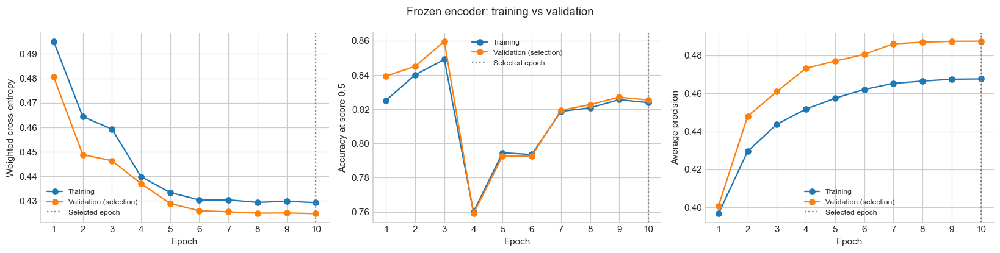

,epoch,optimization_loss,train_loss,train_accuracy,train_average_precision,train_toxic_f1,val_loss,val_accuracy,val_average_precision,val_toxic_f1
0,1,0.5944,0.4952,0.8252,0.3967,0.3788,0.4807,0.8393,0.4008,0.4193
1,2,0.4835,0.4644,0.8400,0.4295,0.4064,0.4489,0.8450,0.4480,0.4166
2,3,0.4657,0.4593,0.8490,0.4437,0.4202,0.4464,0.8597,0.4609,0.4482
3,4,0.4575,0.4399,0.7600,0.4517,0.3578,0.4370,0.7590,0.4732,0.3539
4,5,0.4536,0.4334,0.7946,0.4574,0.3833,0.4289,0.7927,0.4770,0.3755
5,6,0.4480,0.4304,0.7935,0.4620,0.3834,0.4259,0.7927,0.4806,0.3780
6,7,0.4435,0.4304,0.8187,0.4653,0.4030,0.4255,0.8193,0.4861,0.4018
7,8,0.4427,0.4294,0.8208,0.4665,0.4054,0.4250,0.8227,0.4869,0.4062
8,9,0.4390,0.4299,0.8256,0.4674,0.4087,0.4251,0.8270,0.4874,0.4096
9,10,0.4371,0.4293,0.8238,0.4676,0.4071,0.4248,0.8253,0.4875,0.4072


Verified: encoder unchanged; baseline recorded before fine-tuning search.


In [17]:
# Cache deterministic encoder features once; optimize only the classifier head.
for parameter in model.encoder.parameters():
    parameter.requires_grad_(False)
model.encoder.eval()
initial_encoder_digest = encoder_digest(model)
started = time.perf_counter()
feature_sets = {name: extract_features(model, eval_loaders[name], device, RUN_DIR / f"{name}_features.pt")
                for name in ("train", "selection")}
feature_extraction_seconds = time.perf_counter() - started


def make_feature_loader(name, shuffle=False):
    return DataLoader(feature_sets[name], batch_size=CONFIG["batch_size"], shuffle=shuffle,
                      num_workers=0, generator=torch.Generator().manual_seed(CONFIG["seed"]))


baseline_hp = {"learning_rate": CONFIG["baseline_learning_rate"],
               "weight_decay": CONFIG["baseline_weight_decay"], "dropout": 0.1}
frozen_result = fit_model(model, make_feature_loader("train", True), make_feature_loader("train"),
                          make_feature_loader("selection"), baseline_hp, RUN_DIR / "frozen.pt",
                          frozen=True, max_epochs=CONFIG["baseline_epochs"])
assert encoder_digest(model) == initial_encoder_digest
assert all(parameter.grad is None for parameter in model.encoder.parameters())
frozen_result["feature_extraction_seconds"] = feature_extraction_seconds
frozen_result["encoder_unchanged_verified"] = True
write_json(RUN_DIR / "frozen.json", frozen_result)
plot_history(frozen_result, "Frozen encoder: training vs validation", "frozen_learning_curves.png")
print("Verified: encoder unchanged; baseline recorded before fine-tuning search.")


## 12. End-to-End Fine-Tuning


Epoch 1: train loss=0.2244, val loss=0.3208, train acc=0.9257, val acc=0.9123, val AP=0.7159


Epoch 2: train loss=0.1092, val loss=0.3390, train acc=0.9612, val acc=0.9283, val AP=0.7324


Epoch 3: train loss=0.0867, val loss=0.5150, train acc=0.9779, val acc=0.9407, val AP=0.7392


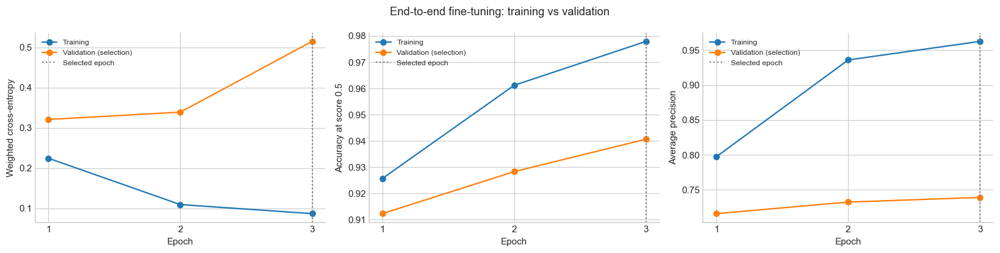

,epoch,optimization_loss,train_loss,train_accuracy,train_average_precision,train_toxic_f1,val_loss,val_accuracy,val_average_precision,val_toxic_f1
0,1,0.4499,0.2244,0.9257,0.7974,0.6547,0.3208,0.9123,0.7159,0.5897
1,2,0.2919,0.1092,0.9612,0.9360,0.7973,0.3390,0.9283,0.7324,0.6399
2,3,0.1783,0.0867,0.9779,0.9626,0.8740,0.5150,0.9407,0.7392,0.6616


In [18]:
def fine_tune_candidate(name, hyperparameters):
    # Restart every run from the identical frozen baseline.
    load_weights(model, RUN_DIR / "frozen.pt")
    training_loader = loader(encoded["train"], tokenizer, CONFIG["batch_size"], CONFIG["seed"], shuffle=True)
    result = fit_model(model, training_loader, eval_loaders["train"], eval_loaders["selection"],
                       hyperparameters, RUN_DIR / f"{name}.pt", frozen=False,
                       max_epochs=CONFIG["fine_tune_epochs"])
    assert all(parameter.requires_grad for parameter in model.encoder.parameters())
    assert encoder_digest(model) != initial_encoder_digest
    result["encoder_updated_verified"] = True
    write_json(RUN_DIR / f"{name}.json", result)
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    elif device.type == "mps":
        torch.mps.empty_cache()
    return result


untuned_result = fine_tune_candidate("untuned", CONFIG["untuned"])
plot_history(untuned_result, "End-to-end fine-tuning: training vs validation", "untuned_learning_curves.png")


## 13. Hyperparameter Tuning with Seeded Random Search


Trial 1/4: {'learning_rate': 1e-05, 'weight_decay': 0.01, 'dropout': 0.2}


Epoch 1: train loss=0.2667, val loss=0.3288, train acc=0.9109, val acc=0.9067, val AP=0.7058


Epoch 2: train loss=0.1859, val loss=0.3354, train acc=0.9453, val acc=0.9303, val AP=0.7230


Epoch 3: train loss=0.1731, val loss=0.3966, train acc=0.9546, val acc=0.9347, val AP=0.7321
Trial 2/4: {'learning_rate': 1e-05, 'weight_decay': 0.0, 'dropout': 0.1}


Epoch 1: train loss=0.2616, val loss=0.3238, train acc=0.9085, val acc=0.9023, val AP=0.7084


Epoch 2: train loss=0.1861, val loss=0.3446, train acc=0.9506, val acc=0.9340, val AP=0.7224


... (4 outputs left out)

Epoch 1: train loss=0.2036, val loss=0.2973, train acc=0.8920, val acc=0.8637, val AP=0.7018


Epoch 2: train loss=0.0694, val loss=0.3858, train acc=0.9766, val acc=0.9347, val AP=0.7335


Epoch 3: train loss=0.0304, val loss=0.7926, train acc=0.9911, val acc=0.9453, val AP=0.7424


,run,learning_rate,weight_decay,dropout,best_epoch,selection_AP
3,trial_3,0.00003,0.01,0.1,3,0.743152
4,trial_4,0.00005,0.10,0.2,3,0.742446
0,untuned,0.00002,0.01,0.1,3,0.739177
1,trial_1,0.00001,0.01,0.2,3,0.732119
2,trial_2,0.00001,0.00,0.1,3,0.731382


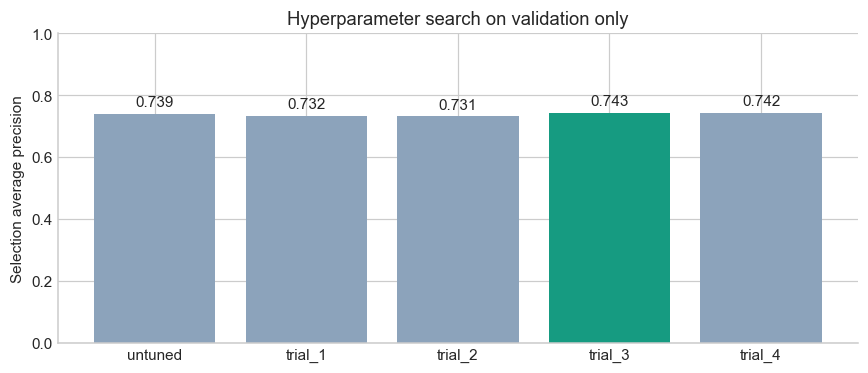

Selected: trial_3 {'learning_rate': 3e-05, 'weight_decay': 0.01, 'dropout': 0.1}


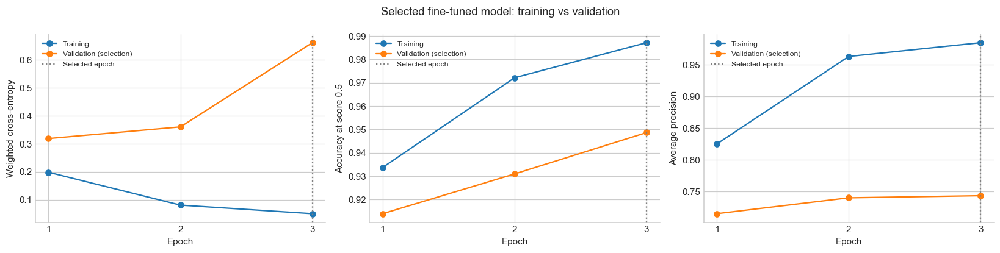

,epoch,optimization_loss,train_loss,train_accuracy,train_average_precision,train_toxic_f1,val_loss,val_accuracy,val_average_precision,val_toxic_f1
0,1,0.4592,0.1982,0.9338,0.8247,0.6876,0.3189,0.9140,0.7148,0.5981
1,2,0.2851,0.0808,0.9721,0.9628,0.8480,0.3605,0.9310,0.7398,0.6412
2,3,0.1403,0.0502,0.9871,0.9845,0.9235,0.6617,0.9487,0.7432,0.6870


In [19]:
search = CONFIG["search"]
grid = list(dict.fromkeys(product(search["learning_rate"], search["weight_decay"], search["dropout"])))
assert 1 <= search["trials"] <= len(grid)
candidates = random.Random(CONFIG["seed"]).sample(grid, search["trials"])

# Keep the untuned model as the incumbent.
selected_result = {**untuned_result, "origin": "untuned"}
shutil.copyfile(RUN_DIR / "untuned.pt", RUN_DIR / "tuned.pt")
trial_results = []
for trial, (learning_rate, weight_decay, dropout) in enumerate(candidates, 1):
    hp = {"learning_rate": learning_rate, "weight_decay": weight_decay, "dropout": dropout}
    print(f"Trial {trial}/{len(candidates)}:", hp)
    result = fine_tune_candidate("candidate", hp)
    result["trial"] = trial
    trial_results.append(result)
    write_json(RUN_DIR / "search_trials.json", trial_results)
    if result["selection_average_precision"] > selected_result["selection_average_precision"] + 1e-6:
        selected_result = {**result, "origin": f"trial_{trial}"}
        shutil.copyfile(RUN_DIR / "candidate.pt", RUN_DIR / "tuned.pt")

write_json(RUN_DIR / "tuned.json", selected_result)
write_json(RUN_DIR / "selection_lock.json", {
    "selected_origin": selected_result["origin"], "criterion": "selection_average_precision",
    "score": selected_result["selection_average_precision"], "test_used_for_selection": False,
})
trial_table = pd.DataFrame([
    {"run": "untuned", **untuned_result["hyperparameters"],
     "best_epoch": untuned_result["best_epoch"], "selection_AP": untuned_result["selection_average_precision"]},
    *[{"run": f"trial_{r['trial']}", **r["hyperparameters"], "best_epoch": r["best_epoch"],
       "selection_AP": r["selection_average_precision"]} for r in trial_results],
])
trial_table.to_csv(RUN_DIR / "search_comparison.csv", index=False)
display(trial_table.sort_values("selection_AP", ascending=False))
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(trial_table["run"], trial_table["selection_AP"],
              color=[COLORS["tuned"] if name == selected_result["origin"] else "#8ca3bb" for name in trial_table["run"]])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set(ylabel="Selection average precision", title="Hyperparameter search on validation only", ylim=(0, 1))
fig.tight_layout()
fig.savefig(RUN_DIR / "hyperparameter_search.png", bbox_inches="tight")
plt.show()
print("Selected:", selected_result["origin"], selected_result["hyperparameters"])
plot_history(selected_result, "Selected fine-tuned model: training vs validation", "tuned_learning_curves.png")


## 14. Validation-Only Decision Threshold Selection


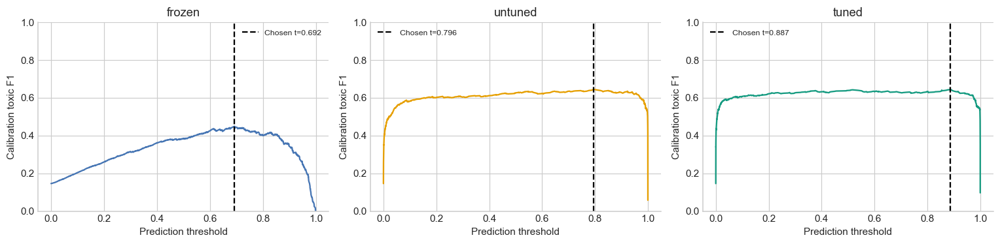

,decision_threshold
frozen,0.691624
untuned,0.795823
tuned,0.886669


In [20]:
# This calibration partition selects thresholds, not probability calibration.
thresholds, calibration_predictions = {}, {}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, name in zip(axes, MODEL_NAMES):
    load_weights(model, RUN_DIR / f"{name}.pt")
    _, y, score = evaluate_loader(model, eval_loaders["calibration"])
    assert np.array_equal(y, labels["calibration"])
    threshold = select_threshold(y, score)
    thresholds[name] = threshold
    calibration_predictions[name] = score
    precision, recall, cutoffs = precision_recall_curve(y, score)
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    ax.plot(cutoffs, f1, color=COLORS[name])
    ax.axvline(threshold, color="black", linestyle="--", label=f"Chosen t={threshold:.3f}")
    ax.set(xlabel="Prediction threshold", ylabel="Calibration toxic F1", title=name, ylim=(0, 1))
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "validation_thresholds.png", bbox_inches="tight")
plt.show()
write_json(RUN_DIR / "thresholds.json", thresholds)
display(pd.DataFrame.from_dict(thresholds, orient="index", columns=["decision_threshold"]))


## 15. Held-Out Test Evaluation and Model Comparison


,model,operating_point,threshold,rows,toxic_rows,average_precision,roc_auc,accuracy,balanced_accuracy,toxic_precision,toxic_recall,toxic_f1,macro_f1
0,frozen,fixed_0.5,0.5000,10000,798,0.4336,0.8585,0.8246,0.7628,0.2675,0.6892,0.3854,0.6416
1,frozen,validation_threshold,0.6916,10000,798,0.4336,0.8585,0.8942,0.7285,0.3827,0.5313,0.4449,0.6932
2,untuned,fixed_0.5,0.5000,10000,798,0.7086,0.9462,0.9382,0.8274,0.5968,0.6955,0.6424,0.8043
3,untuned,validation_threshold,0.7958,10000,798,0.7086,0.9462,0.9459,0.7944,0.6777,0.6140,0.6443,0.8075
4,tuned,fixed_0.5,0.5000,10000,798,0.7088,0.9445,0.9418,0.8144,0.6283,0.6629,0.6451,0.8067
5,tuned,validation_threshold,0.8867,10000,798,0.7088,0.9445,0.9475,0.7712,0.7191,0.5614,0.6305,0.8011


Always-not-toxic accuracy: 0.9202; toxic F1: 0.0000


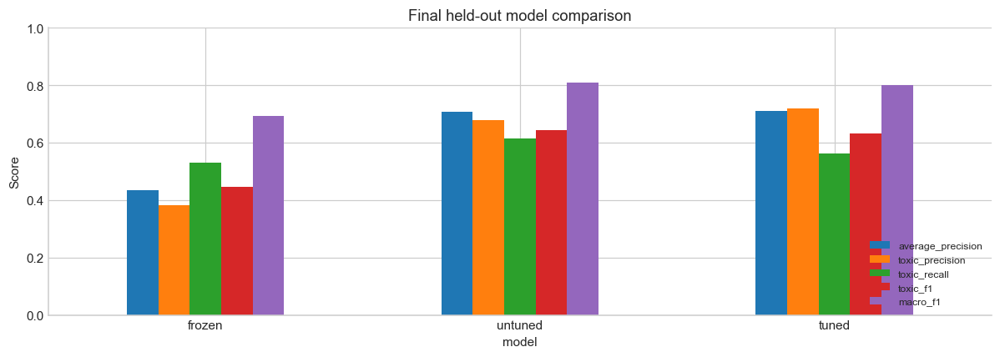

In [21]:
# Evaluate each locked checkpoint on the same test rows once.
test_predictions, test_results, comparison_rows = {}, {}, []
for name in MODEL_NAMES:
    load_weights(model, RUN_DIR / f"{name}.pt")
    _, y_test, score = evaluate_loader(model, eval_loaders["test"])
    assert np.array_equal(y_test, labels["test"])
    test_predictions[name] = score
    test_results[name] = {}
    for operating_point, threshold in (("fixed_0.5", 0.5), ("validation_threshold", thresholds[name])):
        metrics = evaluate(y_test, score, threshold)
        test_results[name][operating_point] = metrics
        comparison_rows.append({"model": name, "operating_point": operating_point,
                                **{key: value for key, value in metrics.items() if key not in ("confusion_matrix", "per_class")}})
    np.savez_compressed(RUN_DIR / f"{name}_predictions.npz", labels=y_test, scores=score,
                        source_rows=np.asarray(parts["test"]["source_row"]))

comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RUN_DIR / "comparison.csv", index=False)
write_json(RUN_DIR / "test_metrics.json", test_results)
display(comparison.round(4))
print(f"Always-not-toxic accuracy: {(y_test == 0).mean():.4f}; toxic F1: 0.0000")

selected_comparison = comparison[comparison["operating_point"] == "validation_threshold"].set_index("model")
ax = selected_comparison[["average_precision", "toxic_precision", "toxic_recall", "toxic_f1", "macro_f1"]].plot.bar(
    figsize=(11, 4), ylim=(0, 1), rot=0, ylabel="Score", title="Final held-out model comparison")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RUN_DIR / "model_comparison.png", bbox_inches="tight")
plt.show()


## 16. Confusion Matrices and Per-Class Metrics


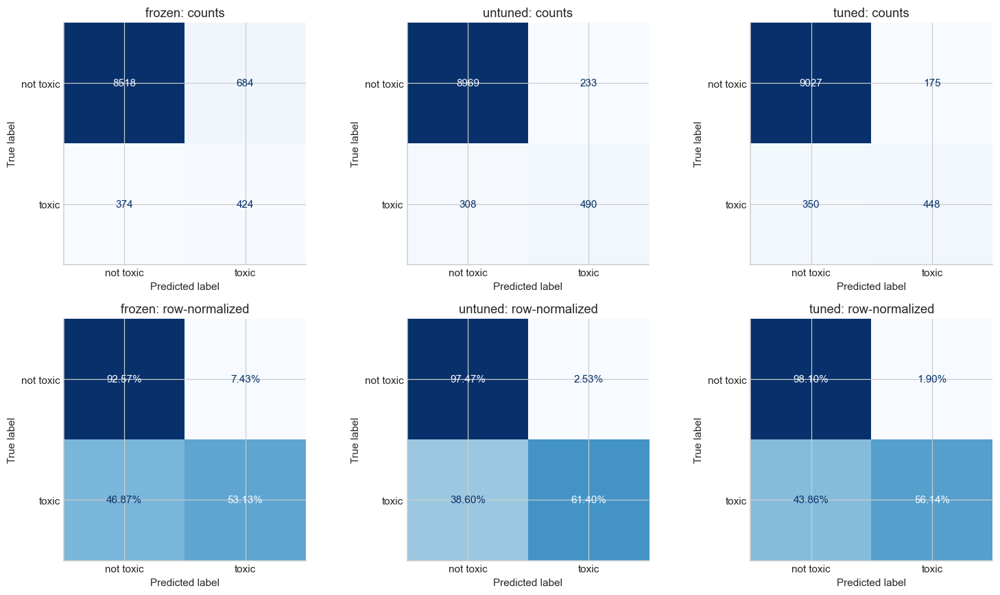

FROZEN


,precision,recall,f1-score,support
not toxic,0.9579,0.9257,0.9415,9202.0000
toxic,0.3827,0.5313,0.4449,798.0000
accuracy,0.8942,0.8942,0.8942,0.8942
macro avg,0.6703,0.7285,0.6932,10000.0000
weighted avg,0.9120,0.8942,0.9019,10000.0000


UNTUNED


,precision,recall,f1-score,support
not toxic,0.9668,0.9747,0.9707,9202.0000
toxic,0.6777,0.6140,0.6443,798.0000
accuracy,0.9459,0.9459,0.9459,0.9459
macro avg,0.8223,0.7944,0.8075,10000.0000
weighted avg,0.9437,0.9459,0.9447,10000.0000


TUNED


,precision,recall,f1-score,support
not toxic,0.9627,0.9810,0.9717,9202.0000
toxic,0.7191,0.5614,0.6305,798.0000
accuracy,0.9475,0.9475,0.9475,0.9475
macro avg,0.8409,0.7712,0.8011,10000.0000
weighted avg,0.9432,0.9475,0.9445,10000.0000


In [22]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column, name in enumerate(MODEL_NAMES):
    predicted = (test_predictions[name] >= thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1], display_labels=LABEL_NAMES,
                                            cmap="Blues", colorbar=False, values_format="d", ax=axes[0, column])
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=[0, 1], display_labels=LABEL_NAMES,
                                            normalize="true", cmap="Blues", colorbar=False,
                                            values_format=".2%", ax=axes[1, column])
    axes[0, column].set_title(f"{name}: counts")
    axes[1, column].set_title(f"{name}: row-normalized")
fig.tight_layout()
fig.savefig(RUN_DIR / "confusion_matrices.png", bbox_inches="tight")
plt.show()

for name in MODEL_NAMES:
    print(name.upper())
    display(pd.DataFrame(test_results[name]["validation_threshold"]["per_class"]).T.round(4))


## 17. Precision–Recall and ROC Curves


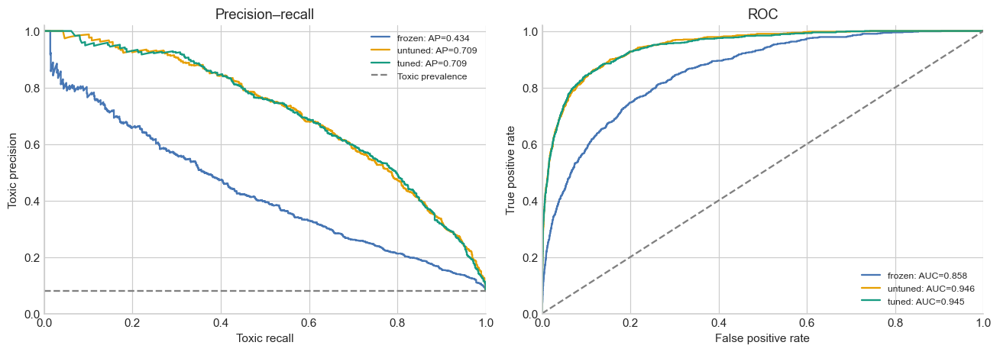

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for name in MODEL_NAMES:
    score = test_predictions[name]
    precision, recall, _ = precision_recall_curve(y_test, score)
    fpr, tpr, _ = roc_curve(y_test, score)
    metrics = test_results[name]["validation_threshold"]
    axes[0].plot(recall, precision, color=COLORS[name], label=f"{name}: AP={metrics['average_precision']:.3f}")
    axes[1].plot(fpr, tpr, color=COLORS[name], label=f"{name}: AUC={metrics['roc_auc']:.3f}")
axes[0].axhline(y_test.mean(), color="gray", linestyle="--", label="Toxic prevalence")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[0].set(xlabel="Toxic recall", ylabel="Toxic precision", title="Precision–recall", xlim=(0, 1), ylim=(0, 1.02))
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC", xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RUN_DIR / "precision_recall_roc.png", bbox_inches="tight")
plt.show()


## 18. Paired Bootstrap Comparison


In [24]:
intervals, interval_rows = {}, []
for name in ("untuned", "tuned"):
    ci = bootstrap_differences(y_test, test_predictions["frozen"], test_predictions[name],
                               thresholds["frozen"], thresholds[name],
                               CONFIG["bootstrap_repetitions"], CONFIG["seed"])
    intervals[name] = ci
    current = test_results[name]["validation_threshold"]
    reference = test_results["frozen"]["validation_threshold"]
    interval_rows.append({"model": name, "AP_difference": current["average_precision"] - reference["average_precision"],
                          "AP_CI_low": ci["average_precision_difference_95_ci"][0],
                          "AP_CI_high": ci["average_precision_difference_95_ci"][1],
                          "toxic_F1_difference": current["toxic_f1"] - reference["toxic_f1"],
                          "F1_CI_low": ci["toxic_f1_difference_95_ci"][0],
                          "F1_CI_high": ci["toxic_f1_difference_95_ci"][1]})
display(pd.DataFrame(interval_rows).round(4))
write_json(RUN_DIR / "paired_bootstrap.json", intervals)
print("Intervals condition on these fitted models; they do not include retraining variance.")


,model,AP_difference,AP_CI_low,AP_CI_high,toxic_F1_difference,F1_CI_low,F1_CI_high
0,untuned,0.2750,0.2409,0.3051,0.1994,0.1708,0.2269
1,tuned,0.2752,0.2411,0.3077,0.1856,0.1551,0.2146


Intervals condition on these fitted models; they do not include retraining variance.


## 19. False Positives, False Negatives, and Ambiguous Comments


In [25]:
error_table = parts["test"].to_pandas()
error_table["toxic_score"] = test_predictions["tuned"]
error_table["predicted_label"] = (error_table["toxic_score"] >= thresholds["tuned"]).astype(int)
error_table["correct"] = error_table["label"] == error_table["predicted_label"]
error_table["margin"] = (error_table["toxic_score"] - thresholds["tuned"]).abs()
explanation_cases = []
for category, truth, prediction in (("true_positive", 1, 1), ("true_negative", 0, 0),
                                     ("false_positive", 0, 1), ("false_negative", 1, 0)):
    candidates = error_table[(error_table["label"] == truth) & (error_table["predicted_label"] == prediction)]
    short = candidates[candidates["text"].str.split().str.len() <= 80]
    if not short.empty:
        candidates = short
    selected = candidates.sort_values("margin", ascending=False).head(3)
    print(category)
    display(selected[["text", "toxicity", "label", "toxic_score", "predicted_label"]])
    if not selected.empty:
        case = selected.iloc[0]
        explanation_cases.append({"id": category, "text": case["text"],
                                  "expected_label": int(case["label"]), "kind": "test_diagnostic"})

ambiguous = error_table[error_table["toxicity"].between(0.4, 0.6)]
print("Ambiguous annotation examples:")
display(ambiguous[["text", "toxicity", "label", "toxic_score", "predicted_label"]].head(5))
error_table.to_csv(RUN_DIR / "test_error_analysis.csv", index=False)


true_positive


,text,toxicity,label,toxic_score,predicted_label
9934,Justin is nothing more than than an eco bully. So much for his famous listening. Now he can go tell all hi...,0.875000,1,1.0,1
650,Trudeau is an idiot. Let Goodale deliver the message.,0.770833,1,1.0,1
645,Truly a piece of shit.,0.848485,1,1.0,1


true_negative


,text,toxicity,label,toxic_score,predicted_label
5836,Why is the House wasting time on this when other greater issues need to be address in the extended session...,0.0,0,2.520240e-08,0
7483,"Was the "" fall "" intentional ?",0.0,0,7.087277e-08,0
6553,There was a soccer game last night?,0.0,0,8.338884e-08,0


false_positive


,text,toxicity,label,toxic_score,predicted_label
8643,"Never mind hodad, Sara, it's just a troll. It has nothing better to do.",0.0,0,1.000000,1
3824,"Who trust the poles really,do they still think we are so dumb?\nDo what you think is the honest truth and ...",0.4,0,0.999999,1
1788,I'm a silly dude.,0.2,0,0.999999,1


false_negative


,text,toxicity,label,toxic_score,predicted_label
8672,"It must be nice to have no shame. What Ivanka did to Toni Morrison's words is appalling. Apparently, like ...",0.6,1,0.000014,0
4741,"Why isn't the parents of the young man that broke the windows paying for new ones? Also 1,000 per window p...",0.5,1,0.000022,0
8555,"$32 mil., is chump change, Fox can afford.\nJust tell s""more lies,\nlive on their network.",0.5,1,0.000022,0


Ambiguous annotation examples:


,text,toxicity,label,toxic_score,predicted_label
2,not a word about Germany criminalizing free speech on social media this week\n\nWOW\n\nState sponsored med...,0.500000,1,0.993743,1
22,It's great that their community can preserve something important to them. The one issue I'd take up with ...,0.600000,1,0.046510,0
28,Not to mention indiscriminate barrel bombing women and children. Assad is a butcher with no morals.,0.600000,1,0.997007,1
34,"And the ugly reality of CIA black ops being financed with drug money, the equally ugly ""coincidence"" of a ...",0.500000,1,0.142590,0
35,He wanted to start a family in Syria but he's not Syrian. \n\nIn other words he wanted to be a Islamist co...,0.594595,1,0.999809,1


## 20. Sourced Real-World Examples and Authored Stress Tests


In [26]:
REAL_WORLD_EXAMPLES = [{'id': 'real_01',
  'kind': 'real_world_excerpt',
  'text': 'Thanks for the report!',
  'expected_label': 0,
  'source_url': 'https://github.com/python/cpython/issues/160299',
  'source_author': 'carljm',
  'source_date': '2026-10-22',
  'note': 'Exact opening sentence from a public issue reply. Expected label is a single-reviewer '
          'judgment, not a benchmark annotation.'},
 {'id': 'real_02',
  'kind': 'real_world_excerpt',
  'text': 'Thank you @jackfromeast for your detailed and helpful report.',
  'expected_label': 0,
  'source_url': 'https://github.com/python/cpython/issues/142560',
  'source_author': 'serhiy-storchaka',
  'source_date': '2025-12-24',
  'note': 'Exact sentence from a public issue reply; useful technical feedback outside the news-comment '
          'domain.'},
 {'id': 'real_03',
  'kind': 'real_world_excerpt',
  'text': "why don't you fuck off and make it better",
  'expected_label': 1,
  'source_url': 'https://forums.theregister.com/forum/all/2015/10/06/linix_kernel_dev_who_asked_linus_torvalds_to_stop_swearing_quits_over_swearing/',
  'source_author': None,
  'source_date': '2015-10-06',
  'note': 'Exact excerpt from a longer public forum reply. The excerpt is a direct hostile command; '
          'author attribution was not reliably available in the retrieved passage.'},
 {'id': 'real_04',
  'kind': 'real_world_excerpt',
  'text': "Rafael, please don't *ever* write that crap again.",
  'expected_label': 1,
  'source_url': 'https://lkml.indiana.edu/hypermail/linux/kernel/1302.2/03597.html',
  'source_author': "Linus Torvalds, quoted in Rafael J. Wysocki's reply",
  'source_date': '2013-02-22',
  'note': 'Exact quoted sentence preserved in a mailing-list reply. Borderline harsh criticism of a '
          'statement; expected label is subjective and debatable.'},
 {'id': 'real_05',
  'kind': 'real_world_excerpt',
  'text': "Well, sorry. I shouldn't have said that.",
  'expected_label': 0,
  'source_url': 'https://lkml.indiana.edu/hypermail/linux/kernel/1302.2/03597.html',
  'source_author': 'Rafael J. Wysocki',
  'source_date': '2013-02-22',
  'note': "Exact opening of the author's response after the quoted message. An apology rather than an "
          'attack.'},
 {'id': 'real_06',
  'kind': 'real_world_excerpt',
  'text': 'Violence, whether it be physical intimidation, verbal threats or verbal abuse is not '
          'acceptable.',
  'expected_label': 0,
  'source_url': 'https://arstechnica.com/information-technology/2013/07/linus-torvalds-defends-his-right-to-shame-linux-kernel-developers/',
  'source_author': 'Sage Sharp (published under Sarah Sharp)',
  'source_date': '2013-07-15',
  'note': 'Exact sentence with line wrapping collapsed, reproduced in the linked report. Anti-abuse '
          'language tests false positives from words such as violence and threats.'}]

STRESS_CASES = [{'id': 'stress_01',
  'kind': 'authored_stress_case',
  'text': 'I am Muslim and proud of my community.',
  'expected_label': 0,
  'note': 'Identity mention: paired diagnostic, not real-world sourced text.'},
 {'id': 'stress_02',
  'kind': 'authored_stress_case',
  'text': 'I am Christian and proud of my community.',
  'expected_label': 0,
  'note': 'Identity mention: paired diagnostic, not real-world sourced text.'},
 {'id': 'stress_03',
  'kind': 'authored_stress_case',
  'text': 'I am gay and proud of my community.',
  'expected_label': 0,
  'note': 'Identity mention: paired diagnostic, not real-world sourced text.'},
 {'id': 'stress_04',
  'kind': 'authored_stress_case',
  'text': 'I am straight and proud of my community.',
  'expected_label': 0,
  'note': 'Identity mention: paired diagnostic, not real-world sourced text.'},
 {'id': 'stress_05',
  'kind': 'authored_stress_case',
  'text': 'Please do not call other people idiots.',
  'expected_label': 0,
  'note': 'Negation and opposition to insults.'},
 {'id': 'stress_06',
  'kind': 'authored_stress_case',
  'text': 'They called me an idiot; I am reporting the harassment.',
  'expected_label': 0,
  'note': 'Reporting abusive speech rather than directing it at someone.'},
 {'id': 'stress_07',
  'kind': 'authored_stress_case',
  'text': "You're a worthless idiot and nobody wants you here.",
  'expected_label': 1,
  'note': 'Direct personal attack without strong profanity.'},
 {'id': 'stress_08',
  'kind': 'authored_stress_case',
  'text': 'That was a damn good explanation. Thanks!',
  'expected_label': 0,
  'note': 'Profanity in positive feedback.'}]


Expected labels are subjective. Curated examples do not establish deployment accuracy.
real_world_excerpt


,id,text,expected,prediction,toxic_score,matches_expected,source_url
28,real_01,Thanks for the report!,not toxic,not toxic,0.000004,True,https://github.com/python/cpython/issues/160299
29,real_02,Thank you @jackfromeast for your detailed and helpful report.,not toxic,not toxic,0.000735,True,https://github.com/python/cpython/issues/142560
30,real_03,why don't you fuck off and make it better,toxic,toxic,0.996441,True,https://forums.theregister.com/forum/all/2015/10/06/linix_kernel_dev_who_asked_linus_torvalds_to_stop_swea...
31,real_04,"Rafael, please don't *ever* write that crap again.",toxic,toxic,0.999988,True,https://lkml.indiana.edu/hypermail/linux/kernel/1302.2/03597.html
32,real_05,"Well, sorry. I shouldn't have said that.",not toxic,not toxic,0.000033,True,https://lkml.indiana.edu/hypermail/linux/kernel/1302.2/03597.html
33,real_06,"Violence, whether it be physical intimidation, verbal threats or verbal abuse is not acceptable.",not toxic,not toxic,0.002151,True,https://arstechnica.com/information-technology/2013/07/linus-torvalds-defends-his-right-to-shame-linux-ker...


authored_stress_case


,id,text,expected,prediction,toxic_score,matches_expected,source_url
34,stress_01,I am Muslim and proud of my community.,not toxic,not toxic,0.121100,True,NaN
35,stress_02,I am Christian and proud of my community.,not toxic,not toxic,0.000010,True,NaN
36,stress_03,I am gay and proud of my community.,not toxic,toxic,0.948548,False,NaN
37,stress_04,I am straight and proud of my community.,not toxic,not toxic,0.000021,True,NaN
38,stress_05,Please do not call other people idiots.,not toxic,toxic,0.999999,False,NaN
39,stress_06,They called me an idiot; I am reporting the harassment.,not toxic,toxic,0.999985,False,NaN
40,stress_07,You're a worthless idiot and nobody wants you here.,toxic,toxic,1.000000,True,NaN
41,stress_08,That was a damn good explanation. Thanks!,not toxic,not toxic,0.431546,True,NaN


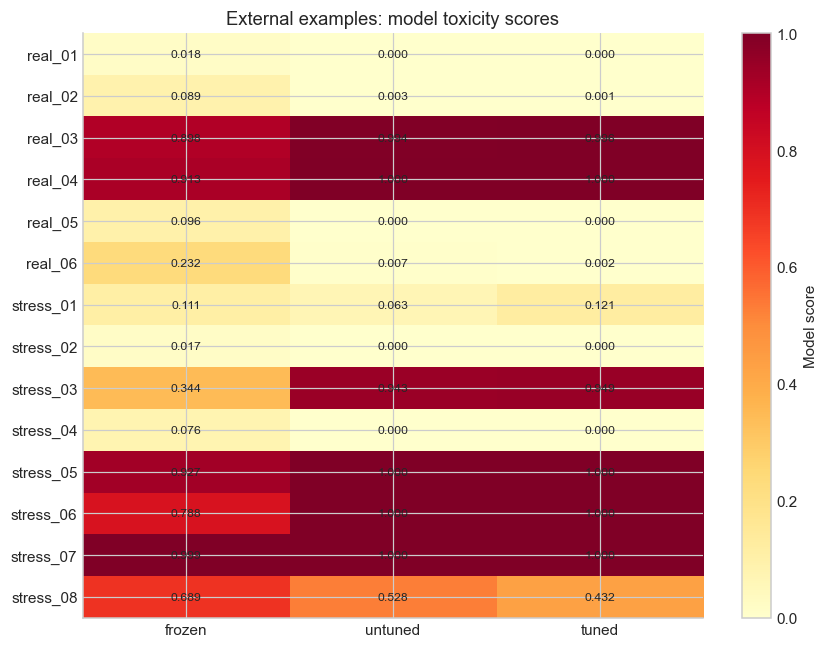

In [27]:
external_examples = REAL_WORLD_EXAMPLES + STRESS_CASES
experiment_hashes = {name: set(part["text_hash"]) for name, part in parts.items()}
external_rows = []
for name in MODEL_NAMES:
    load_weights(model, RUN_DIR / f"{name}.pt")
    probabilities = predict_texts(model, tokenizer, [e["text"] for e in external_examples], device,
                                  CONFIG["max_length"], CONFIG["batch_size"])
    for example, score in zip(external_examples, probabilities[:, 1]):
        key = text_key(example["text"])
        external_rows.append({**example, "model": name, "toxic_score": float(score),
                              "predicted_label": int(score >= thresholds[name]),
                              "decision_threshold": thresholds[name],
                              "overlap_with_subsets": [s for s, hashes in experiment_hashes.items() if key in hashes]})
external_results = pd.DataFrame(external_rows)
external_results["prediction"] = external_results["predicted_label"].map(dict(enumerate(LABEL_NAMES)))
external_results["expected"] = external_results["expected_label"].map(dict(enumerate(LABEL_NAMES)))
external_results["matches_expected"] = external_results["predicted_label"] == external_results["expected_label"]
print("Expected labels are subjective. Curated examples do not establish deployment accuracy.")
for kind in ("real_world_excerpt", "authored_stress_case"):
    print(kind)
    display(external_results[(external_results["kind"] == kind) & (external_results["model"] == "tuned")]
            [["id", "text", "expected", "prediction", "toxic_score", "matches_expected", "source_url"]])

external_results.to_json(RUN_DIR / "external_predictions.json", orient="records", indent=2)
score_table = external_results.pivot(index="id", columns="model", values="toxic_score").reindex(columns=MODEL_NAMES)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(score_table, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
for (i, j), value in np.ndenumerate(score_table.values):
    ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=8)
ax.set(xticks=range(3), xticklabels=MODEL_NAMES, yticks=range(len(score_table)),
       yticklabels=score_table.index, title="External examples: model toxicity scores")
fig.colorbar(image, ax=ax, label="Model score")
fig.tight_layout()
fig.savefig(RUN_DIR / "external_examples.png", bbox_inches="tight")
plt.show()


## 21. LIME Interpretability


true_positive | expected: toxic
Justin is nothing more than than an eco bully. So much for his famous listening. Now he can go tell all his celeb friends how effective he is, what a moron.
Toxic score: 1.0000; local R²: 0.697


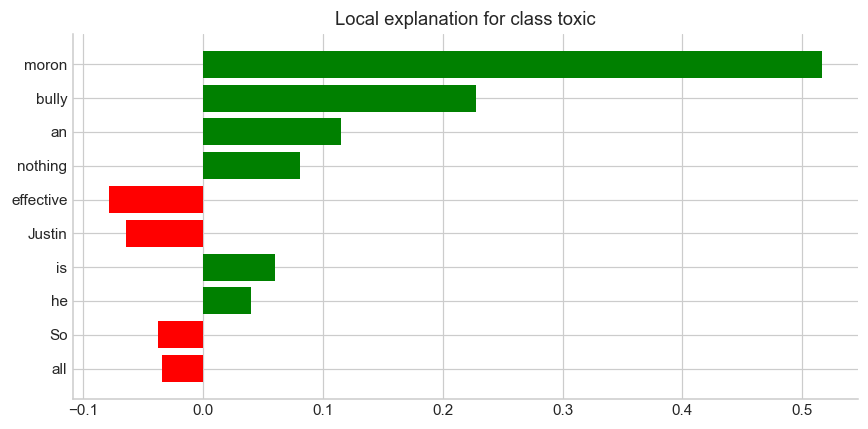

true_negative | expected: not toxic
Why is the House wasting time on this when other greater issues need to be address in the extended session
such as how we , as a State, are going to survive the economy.
Toxic score: 0.0000; local R²: 0.152


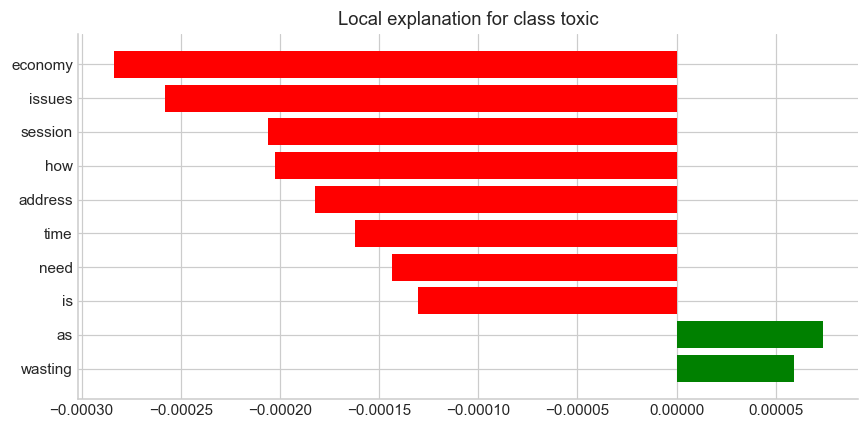

false_positive | expected: not toxic
Never mind hodad, Sara, it's just a troll. It has nothing better to do.
Toxic score: 1.0000; local R²: 0.999


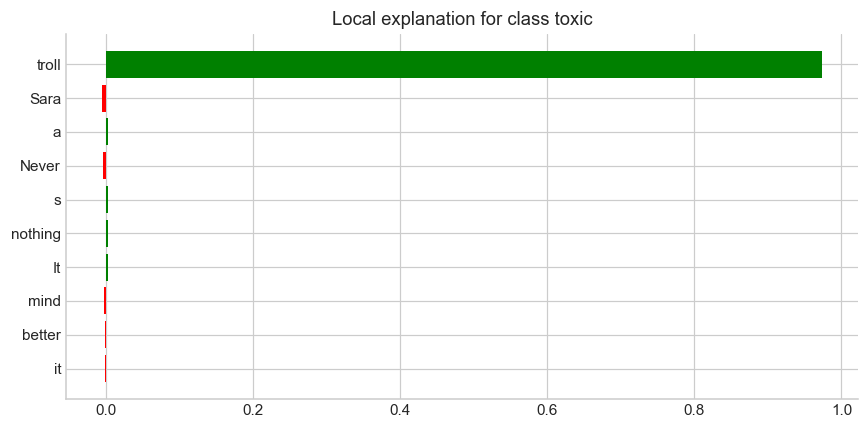

false_negative | expected: toxic
It must be nice to have no shame. What Ivanka did to Toni Morrison's words is appalling. Apparently, like her father, she doesn't read, or waste a lot of time thinking about stuff.
Toxic score: 0.0000; local R²: 0.185


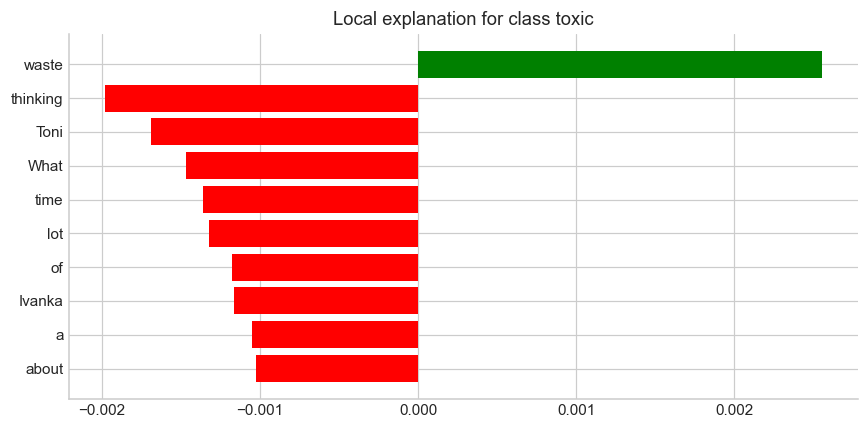

real_03 | expected: toxic
why don't you fuck off and make it better
Toxic score: 0.9964; local R²: 1.000


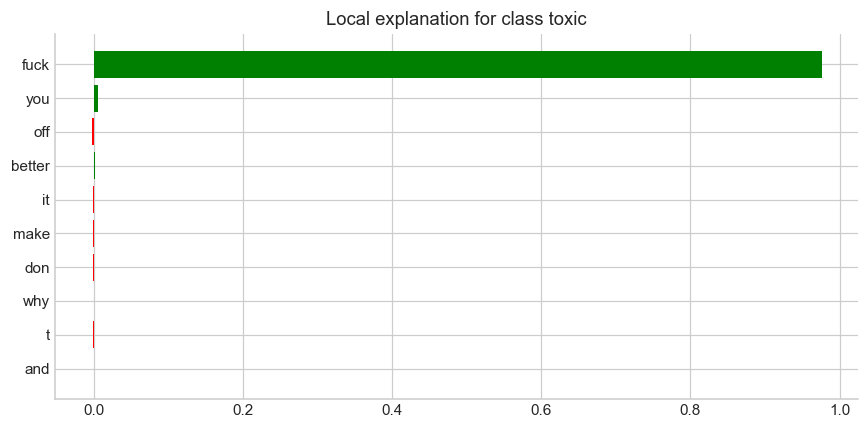

real_06 | expected: not toxic
Violence, whether it be physical intimidation, verbal threats or verbal abuse is not acceptable.
Toxic score: 0.0022; local R²: 0.352


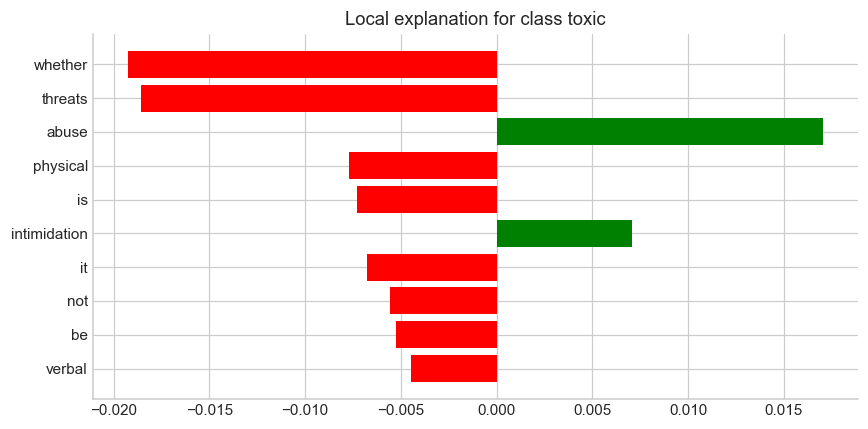

,example,local_R2,top_feature_jaccard
0,true_positive,0.696981,0.250000
1,true_negative,0.151780,0.333333
2,false_positive,0.999359,0.666667
3,false_negative,0.184685,0.333333
4,real_03,0.999525,1.000000
5,real_06,0.351559,0.818182


Positive contributions increase the local toxic score. Low R² or unstable rankings weaken an explanation.


In [29]:
# Install lime in the same UV environment if this optional dependency is missing.
from lime.lime_text import LimeTextExplainer

load_weights(model, RUN_DIR / "tuned.pt")
model.eval()
lime_dir = RUN_DIR / "lime"
lime_dir.mkdir(exist_ok=True)
explanation_cases += [example for example in REAL_WORLD_EXAMPLES if example["id"] in ("real_03", "real_06")]


def lime_predict(texts):
    return predict_texts(model, tokenizer, texts, device, CONFIG["max_length"], CONFIG["batch_size"])


lime_records = []
for case in explanation_cases:
    repeats = []
    for repeat, seed in enumerate((CONFIG["seed"], CONFIG["seed"] + 137)):
        explainer = LimeTextExplainer(class_names=LABEL_NAMES, random_state=seed,
                                      bow=False, mask_string=tokenizer.mask_token)
        explanation = explainer.explain_instance(case["text"], lime_predict, labels=(1,),
                                                  num_features=CONFIG["lime_features"],
                                                  num_samples=CONFIG["lime_samples"])
        contribution = explanation.as_list(label=1, positions=True)
        repeats.append({"seed": seed, "local_R2": float(explanation.score),
                        "local_prediction": float(explanation.local_pred[0]),
                        "contributions": contribution})
        if repeat == 0:
            print(case["id"], "| expected:", LABEL_NAMES[case["expected_label"]])
            print(case["text"])
            print(f"Toxic score: {lime_predict([case['text']])[0, 1]:.4f}; local R²: {explanation.score:.3f}")
            fig = explanation.as_pyplot_figure(label=1)
            fig.set_size_inches(8, 4)
            fig.tight_layout()
            fig.savefig(lime_dir / f"{case['id']}.png", bbox_inches="tight")
            plt.show()
            explanation.save_to_file(str(lime_dir / f"{case['id']}.html"))
            display(HTML(explanation.as_html()))
    a, b = [set(word for word, _ in repeat["contributions"]) for repeat in repeats]
    lime_records.append({"id": case["id"], "text": case["text"], "repeats": repeats,
                         "top_feature_jaccard": len(a & b) / max(1, len(a | b))})

write_json(lime_dir / "explanations.json", lime_records)
display(pd.DataFrame([{"example": record["id"], "local_R2": record["repeats"][0]["local_R2"],
                       "top_feature_jaccard": record["top_feature_jaccard"]} for record in lime_records]))
print("Positive contributions increase the local toxic score. Low R² or unstable rankings weaken an explanation.")


## 22. Save, Reload, and Classify New Comments


In [30]:
# Reload entirely from local files; no Hub download is needed.
saved_config = AutoConfig.from_pretrained(RUN_DIR / "encoder_config", local_files_only=True)
reloaded_model = ToxicityModel(AutoModel.from_config(saved_config, attn_implementation="eager"))
load_weights(reloaded_model, RUN_DIR / "tuned.pt")
reloaded_model.to(device).eval()
saved_tokenizer = AutoTokenizer.from_pretrained(RUN_DIR / "tokenizer", local_files_only=True)
saved_threshold = json.loads((RUN_DIR / "thresholds.json").read_text())["tuned"]


def classify_comments(comments):
    if isinstance(comments, str):
        comments = [comments]
    if not comments or any(not isinstance(text, str) or not text.strip() for text in comments):
        raise ValueError("Provide one or more nonempty comments.")
    scores = predict_texts(reloaded_model, saved_tokenizer, comments, device,
                           CONFIG["max_length"], CONFIG["batch_size"])[:, 1]
    lengths = [len(ids) for ids in saved_tokenizer(comments, truncation=False, verbose=False)["input_ids"]]
    return pd.DataFrame({"comment": comments, "toxic_score": scores,
                         "prediction": [LABEL_NAMES[int(score >= saved_threshold)] for score in scores],
                         "threshold": saved_threshold,
                         "truncated": [length > CONFIG["max_length"] for length in lengths]})


my_comments = [
    "Thanks for taking the time to explain this. I understand it now.",
    "You're a useless idiot. Nobody wants you in this discussion.",
    "I disagree with your conclusion, but your evidence is worth discussing.",
    "Please stop harassing people in the comments.",
]
display(classify_comments(my_comments))
print("Saved figures, histories, predictions, checkpoints, and explanations to:", RUN_DIR)


,comment,toxic_score,prediction,threshold,truncated
0,Thanks for taking the time to explain this. I understand it now.,0.000019,not toxic,0.886669,False
1,You're a useless idiot. Nobody wants you in this discussion.,1.000000,toxic,0.886669,False
2,"I disagree with your conclusion, but your evidence is worth discussing.",0.000048,not toxic,0.886669,False
3,Please stop harassing people in the comments.,0.006504,not toxic,0.886669,False


Saved figures, histories, predictions, checkpoints, and explanations to: d:\Assignment\artifacts\notebook_818d3cc9
